In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
df = pd.read_excel("Sample - Superstore 2.xlsx")

In [3]:
print(df.head())

   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
1       2  CA-2016-152156 2016-11-08 2016-11-11    Second Class    CG-12520   
2       3  CA-2016-138688 2016-06-12 2016-06-16    Second Class    DV-13045   
3       4  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   
4       5  US-2015-108966 2015-10-11 2015-10-18  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   South  FUR-BO-10

In [4]:
print(df.shape)

(9994, 21)


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

In [6]:
print(df.isnull().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [7]:
df = df.dropna()

In [8]:
customer_data = df.groupby('Customer ID').agg({

    'Sales': 'sum',

    'Profit': 'sum',

    'Order ID': 'nunique',

    'Quantity': 'sum'

}).reset_index()

In [9]:
customer_data.columns = [

    'Customer ID',

    'Total Sales',

    'Total Profit',

    'Order Frequency',

    'Total Quantity'

]

In [11]:
customer_data['Average Order Value'] = (

    customer_data['Total Sales'] /

    customer_data['Order Frequency']

)

In [12]:
print(customer_data.head())

  Customer ID  Total Sales  Total Profit  Order Frequency  Total Quantity  \
0    AA-10315     5563.560     -362.8825                5              30   
1    AA-10375     1056.390      277.3824                9              41   
2    AA-10480     1790.512      435.8274                4              36   
3    AA-10645     5086.935      857.8033                6              64   
4    AB-10015      886.156      129.3465                3              13   

   Average Order Value  
0          1112.712000  
1           117.376667  
2           447.628000  
3           847.822500  
4           295.385333  


In [13]:
X = customer_data[[

    'Total Sales',

    'Total Profit',

    'Order Frequency',

    'Average Order Value'

]]

In [14]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [15]:
wcss = []

for i in range(1, 11):

    kmeans = KMeans(

        n_clusters=i,

        random_state=42,

        n_init=10

    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

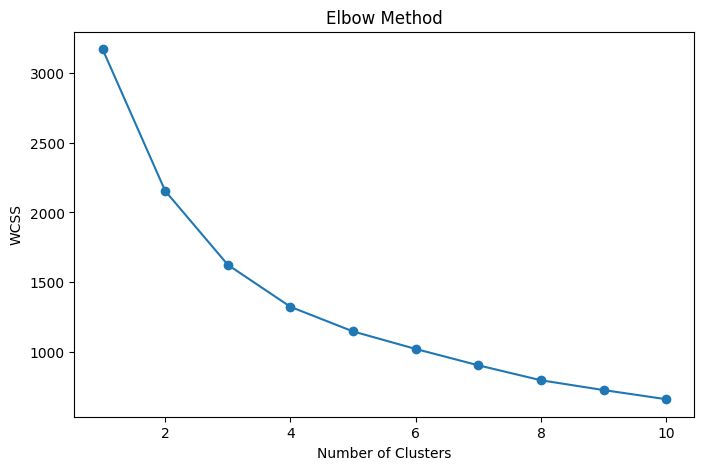

In [16]:
plt.figure(figsize=(8,5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')

plt.xlabel('Number of Clusters')

plt.ylabel('WCSS')

plt.show()

In [17]:
kmeans = KMeans(

    n_clusters=3,

    random_state=42,

    n_init=10

)

customer_data['Cluster'] = kmeans.fit_predict(X_scaled)

In [18]:
print(customer_data.head(10))

  Customer ID  Total Sales  Total Profit  Order Frequency  Total Quantity  \
0    AA-10315     5563.560     -362.8825                5              30   
1    AA-10375     1056.390      277.3824                9              41   
2    AA-10480     1790.512      435.8274                4              36   
3    AA-10645     5086.935      857.8033                6              64   
4    AB-10015      886.156      129.3465                3              13   
5    AB-10060     7755.620     2054.5885                8              56   
6    AB-10105    14473.571     5444.8055               10              73   
7    AB-10150      966.710      313.6597                5              37   
8    AB-10165     1113.838      220.8130                8              48   
9    AB-10255      914.532      264.5675                9              39   

   Average Order Value  Cluster  
0          1112.712000        0  
1           117.376667        0  
2           447.628000        1  
3           847.

In [19]:
cluster_summary = customer_data.groupby('Cluster').agg({

    'Total Sales': 'mean',

    'Total Profit': 'mean',

    'Order Frequency': 'mean',

    'Average Order Value': 'mean',

    'Customer ID': 'count'

}).rename(columns={'Customer ID': 'Number of Customers'})

print(cluster_summary)

         Total Sales  Total Profit  Order Frequency  Average Order Value  \
Cluster                                                                    
0        3560.197683    410.460700         8.453988           438.088333   
1        1450.961347     91.795380         4.485366           334.046156   
2        9503.197604   2016.679433         7.263158          1493.358463   

         Number of Customers  
Cluster                       
0                        326  
1                        410  
2                         57  


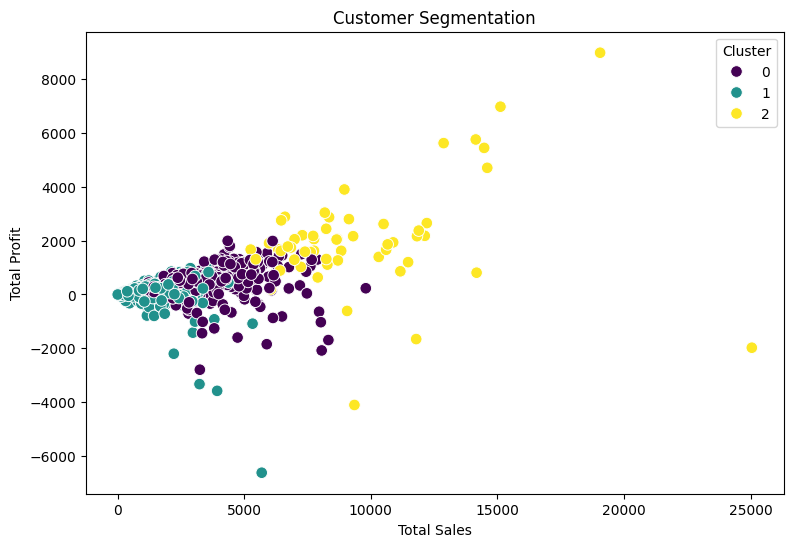

In [20]:
plt.figure(figsize=(9,6))

sns.scatterplot(

    data=customer_data,

    x='Total Sales',

    y='Total Profit',

    hue='Cluster',

    palette='viridis',

    s=70

)

plt.title('Customer Segmentation')

plt.xlabel('Total Sales')

plt.ylabel('Total Profit')

plt.show()

In [21]:
print("CUSTOMER SEGMENTATION PROJECT")

print("-----------------------------")

print("Total Customers:", len(customer_data))

print("Number of Clusters:", customer_data['Cluster'].nunique())

print("\nCustomer Distribution:")

print(customer_data['Cluster'].value_counts().sort_index())

print("\nCluster Summary:")

print(cluster_summary)

CUSTOMER SEGMENTATION PROJECT
-----------------------------
Total Customers: 793
Number of Clusters: 3

Customer Distribution:
Cluster
0    326
1    410
2     57
Name: count, dtype: int64

Cluster Summary:
         Total Sales  Total Profit  Order Frequency  Average Order Value  \
Cluster                                                                    
0        3560.197683    410.460700         8.453988           438.088333   
1        1450.961347     91.795380         4.485366           334.046156   
2        9503.197604   2016.679433         7.263158          1493.358463   

         Number of Customers  
Cluster                       
0                        326  
1                        410  
2                         57  
